# Extended Data Fig. 15 (manuscript's last Extended Data figure), panels c-i: CA1 latent separation vs other variables

Reproduces the MATLAB analysis:

| panel |  content |
|---|---|
| c | separability vs number of CEBRA latent dimensions, the 30 sessions of d-i and Fig. 5 |
| d, e | sep. (start box / whole learning epoch) vs CA1 MUA rate, 2nd maze, running, beginning |
| f, g | sep. vs CA1 d2 in the recall (probe) epoch, running, beginning (n = 26) |
| h, i | sep. vs CA1 d2 in Maze 1 (first maze), running, beginning |


Values are z-scored within animal. Title: Spearman r and p (MATLAB `corr`, Edgeworth/AS 89 p value).
In-panel `r =` is the slope of the robust linear fit (`fitlm(..., 'RobustOpts', 'on')`, bisquare), on z-scored data.

Data: `../csv/FigS15_CI_separation_vars/figS15_scatter.csv`, `../csv/FigS15_CI_separation_vars/figS15_panelc.csv`

In [1]:
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DATADIR, FIGDIR = '../csv/FigS15_CI_separation_vars', '../figure_output/supplementary/FigS15'
os.makedirs(FIGDIR, exist_ok=True)
FONTS = 'fonts'
for f in ['Regular', 'Bold']:   # Helvetica clone (Nimbus Sans), embedded as TrueType
    fp = f'{FONTS}/NimbusSans-{f}.ttf'
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
RC = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Nimbus Sans TT', 'Arial'], 'font.size': 7,
      'axes.linewidth': 1, 'xtick.major.width': 1, 'ytick.major.width': 1, 'xtick.major.size': 2.5,
      'ytick.major.size': 2.5, 'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False}
BLUE, GREY, BLACK, MUTED, RED = '#2a78d6', '#b4b2a9', '#1f1f1d', '#8a887f', '#d62728'

sc = pd.read_csv(f'{DATADIR}/figS15_scatter.csv')
pc = pd.read_csv(f'{DATADIR}/figS15_panelc.csv')

In [2]:
# --- MATLAB-equivalent statistics -------------------------------------------------------------
def spearman_matlab(x, y):
    # corr(x, y, 'Type', 'Spearman'): rho + two-sided p from the Edgeworth series (AS 89), used by MATLAB for n > 9
    rho = stats.spearmanr(x, y)[0]
    n = len(x); n3 = n * (n * n - 1) / 6
    def upper(S):                     # P(sum d^2 >= S)
        js = np.ceil(S); js += js % 2
        b = 1 / n
        z = (6 * (js - 1) * b / (n * n - 1) - 1) * np.sqrt(1 / b - 1); y2 = z * z
        c = [0.2274, 0.2531, 0.1745, 0.0758, 0.1033, 0.3932, 0.0879, 0.0151, 0.0072, 0.0831, 0.0131, 4.6e-4]
        u = z * b * (c[0] + b * (c[1] + c[2] * b) + y2 * (-c[3] + b * (c[4] + c[5] * b) - y2 * b * (
            c[6] + c[7] * b - y2 * (c[8] - c[9] * b + y2 * b * (c[10] - c[11] * y2)))))
        return float(np.clip(u / np.exp(y2 / 2) + stats.norm.sf(z), 0, 1))
    S = n3 * (1 - rho)
    return rho, min(1.0, 2 * min(upper(S), upper(2 * n3 - S)))


def robustfit_matlab(x, y, tune=4.685):
    # fitlm(x, y, 'RobustOpts', 'on') = robustfit, bisquare weights, leverage-adjusted residuals (DuMouchel & O'Brien)
    bisq = lambda u: (np.abs(u) < 1) * (1 - u ** 2) ** 2
    mads = lambda r, p: np.median(np.sort(np.abs(r))[max(1, p) - 1:]) / 0.6745
    X = np.column_stack([np.ones_like(x), x]); n, p = X.shape
    Q, R = np.linalg.qr(X); b = np.linalg.solve(R, Q.T @ y)
    E = X @ np.linalg.inv(R); h = np.minimum(.9999, (E * E).sum(1)); adj = 1 / np.sqrt(1 - h)
    ols_s = np.linalg.norm(y - X @ b) / np.sqrt(n - p)
    D, b0 = np.sqrt(np.finfo(float).eps), np.zeros(p)
    for _ in range(50):
        if not np.any(np.abs(b - b0) > D * np.maximum(np.abs(b), np.abs(b0))):
            break
        b0 = b; radj = (y - X @ b) * adj
        w = bisq(radj / (mads(radj, p) * tune)); sw = np.sqrt(w)
        b = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]
    radj = (y - X @ b) * adj; st = max(mads(radj, p), np.finfo(float).eps) * tune; u = radj / st
    dl = 1e-4; dphi = ((u + dl) * bisq(u + dl) - (u - dl) * bisq(u - dl)) / (2 * dl)
    m1 = dphi.mean(); m2 = np.sum((1 - h) * (u * bisq(u)) ** 2) / (n - p); K = 1 + (p / n) * (1 - m1) / m1
    rob_s = K * np.sqrt(m2) * st / m1
    sigma = max(rob_s, np.sqrt((ols_s ** 2 * p ** 2 + rob_s ** 2 * n) / (p ** 2 + n)))
    RI = np.linalg.inv(R); se = np.sqrt(np.diag(RI @ RI.T) * sigma ** 2)
    return b, se, 2 * stats.t.sf(np.abs(b / se), n - p)


PANELS = {  # label: (y label, x label)
    'd': ('norm. CA1 sep.\nin start box', 'norm. MUA firing rate (z)'),
    'e': ('norm. CA1 sep.\nduring learning', 'norm. MUA firing rate (z)'),
    'f': ('norm. CA1 sep.\nin start box', 'norm. d$_2$ in recall (z)'),
    'g': ('norm. CA1 sep.\nduring learning', 'norm. d$_2$ in recall (z)'),
    'h': ('norm. CA1 sep.\nin start box', 'norm. d$_2$ in Maze 1 (z)'),
    'i': ('norm. CA1 sep.\nduring learning', 'norm. d$_2$ in Maze 1 (z)'),
}
PUBLISHED = {'d': (0.07, 7.016e-01, 0.12), 'e': (-0.09, 6.431e-01, -0.15), 'f': (0.06, 7.610e-01, 0.07),
             'g': (-0.09, 6.661e-01, -0.09), 'h': (-0.13, 4.959e-01, -0.23), 'i': (-0.21, 2.565e-01, -0.17)}
rows, fits = [], {}
for lab in PANELS:
    d = sc[(sc.panel == lab) & sc.x.notna()]
    rho, p = spearman_matlab(d.x.values, d.y.values)
    b, se, pb = robustfit_matlab(d.x.values, d.y.values)
    pr, pp = stats.pearsonr(d.x, d.y)
    fits[lab] = (d, rho, p, b)
    rows.append(dict(panel=lab, reference=d.reference.iloc[0], n=len(d), spearman_r=rho, spearman_p=p,
                     robust_slope=b[1], robust_slope_se=se[1], robust_slope_p=pb[1], robust_intercept=b[0],
                     pearson_r=pr, pearson_p=pp, published_r=PUBLISHED[lab][0], published_p=PUBLISHED[lab][1],
                     published_r_in=PUBLISHED[lab][2]))

# --- panel c: Friedman over sessions x dims, Dunn-Sidak comparison of each dim vs 16 (MATLAB multcompare)
M = pc.pivot(index='filename', columns='num_cebra', values='accuracy').dropna()
dims = list(M.columns); n_c, k = M.shape
chi2, p_fr = stats.friedmanchisquare(*M.values.T)
mr = np.apply_along_axis(stats.rankdata, 1, M.values).mean(0)
se_r = np.sqrt(k * (k + 1) / (6 * n_c)); m_cmp = k * (k - 1) / 2
p_vs16 = {dm: 1 - (1 - 2 * stats.norm.sf(abs(mr[i] - mr[-1]) / se_r)) ** m_cmp for i, dm in enumerate(dims[:-1])}
sig_dims = [dm for dm, pv in p_vs16.items() if pv < 0.05]
rows.append(dict(panel='c', reference='combined_thin.csv (no .fig)', n=n_c, friedman_chi2=chi2, friedman_p=p_fr,
                 dims_differing_from_16=' '.join(map(str, sig_dims))))
for dm, pv in p_vs16.items():
    rows.append(dict(panel=f'c_dim{dm}_vs16', n=n_c, dunn_sidak_p=pv))
stat_df = pd.DataFrame(rows)
stat_df.to_csv(f'{FIGDIR}/FigS15_statistics.csv', index=False)
print(f'Friedman chi2 = {chi2:.1f}, p = {p_fr:.2e}, n = {n_c} sessions; dims differing from 16: {sig_dims}')
stat_df[stat_df.panel.isin(list(PANELS))][['panel', 'n', 'spearman_r', 'spearman_p', 'published_r', 'published_p',
                                            'robust_slope', 'published_r_in', 'pearson_r']].round(4)

Friedman chi2 = 137.9, p = 1.13e-24, n = 30 sessions; dims differing from 16: [2, 3]


,panel,n,spearman_r,spearman_p,published_r,published_p,robust_slope,published_r_in,pearson_r
0,d,30,0.0727,0.7016,0.07,0.7016,0.1189,0.12,0.1641
1,e,30,-0.0879,0.6431,-0.09,0.6431,-0.1511,-0.15,-0.0532
2,f,26,0.0626,0.7610,0.06,0.7610,0.0746,0.07,0.0796
3,g,26,-0.0885,0.6661,-0.09,0.6661,-0.0852,-0.09,-0.0763
4,h,30,-0.1288,0.4959,-0.13,0.4959,-0.2313,-0.23,-0.1465
5,i,30,-0.2133,0.2565,-0.21,0.2565,-0.1668,-0.17,-0.0926


## c: separability vs number of latent dimensions

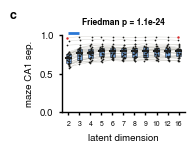

In [3]:
with plt.rc_context(RC):
    # same axes size as panel c in the manuscript (image50.png: 319 x 199 px at 1676 px / 6.48 in)
    W_C, H_C = 319 / (1676 / 6.48), 199 / (1676 / 6.48)          # 1.233 x 0.769 in
    L, B, R, T = 0.5, 0.42, 0.1, 0.3                              # margins (in)
    fw, fh = L + W_C + R, B + H_C + T
    fig = plt.figure(figsize=(fw, fh))
    ax = fig.add_axes([L / fw, B / fh, W_C / fw, H_C / fh])
    BW = 11 / 28.6                     # box width as in the manuscript: 11 px boxes, 28.6 px between dimensions
    pos = np.arange(k)
    for _, r in M.iterrows():
        ax.plot(pos, r.values, color=GREY, lw=0.3, alpha=0.6, zorder=1)
    rng = np.random.default_rng(0)
    for i, dm in enumerate(dims):
        v = M[dm].values
        q1, med, q3 = np.percentile(v, [25, 50, 75], method='hazen')   # MATLAB quantile convention
        iqr = q3 - q1; out = (v > q3 + 1.5 * iqr) | (v < q1 - 1.5 * iqr)
        ax.add_patch(plt.Rectangle((i - BW / 2, q1), BW, iqr, fc=BLUE, ec=BLACK, lw=0.6, alpha=0.6, zorder=2))
        ax.plot([i - BW / 2, i + BW / 2], [med, med], color=BLACK, lw=1.5, zorder=3)
        jit = rng.uniform(-0.12, 0.12, len(v))
        ax.scatter(i + jit[~out], v[~out], s=1.5, color=BLACK, lw=0, zorder=4)
        ax.scatter(i + jit[out], v[out], s=3, color=RED, lw=0, zorder=4)
    if sig_dims:
        i0, i1 = dims.index(sig_dims[0]), dims.index(sig_dims[-1])
        ax.plot([i0, i1], [1.03, 1.03], color=BLUE, lw=2, solid_capstyle='butt', clip_on=False)
    ax.set_xticks(pos); ax.set_xticklabels([str(d) for d in dims], fontsize=5)
    ax.set_xlim(-0.6, k - 0.4); ax.set_ylim(0, 1)
    ax.set_xlabel('latent dimension'); ax.set_ylabel('maze CA1 sep.')
    ax.set_title(f'Friedman p = {p_fr:.1e}', fontsize=6, fontweight='bold', pad=8)
    ax.text(-0.42, 1.18, 'c', transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom')
    fig.savefig(f'{FIGDIR}/FigS15_C_separation_vars.pdf', bbox_inches='tight')
    plt.show()

## d–i: separation vs MUA rate and d2

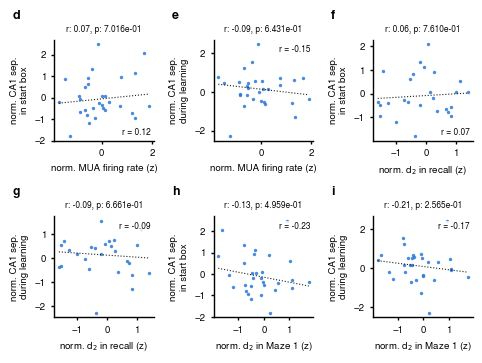

In [4]:
def pstr(p):
    return f'{p:.3e}'

with plt.rc_context(RC):
    fig, axes = plt.subplots(2, 3, figsize=(5.4, 3.6), gridspec_kw={'wspace': 0.6, 'hspace': 0.75})
    for ax, lab in zip(axes.flat, PANELS):                 # d e f / g h i
        d, rho, p, b = fits[lab]
        ax.scatter(d.x, d.y, s=6, color=BLUE, alpha=0.85, lw=0, zorder=2)
        xs = np.linspace(d.x.min(), d.x.max(), 50)
        ax.plot(xs, b[0] + b[1] * xs, color=BLACK, lw=0.8, ls='-' if p < 0.05 else ':', zorder=3)
        sig = p < 0.05
        ax.set_title(f'r: {rho:.2f}, p: {pstr(p)}' + (' *' if sig else ''), fontsize=6,
                     fontweight='bold' if sig else 'normal')
        ax.text(0.97, 0.06 if b[1] > 0 else 0.88, f'r = {b[1]:.2f}', transform=ax.transAxes, ha='right', fontsize=6,
                bbox=dict(fc='white', ec='none', pad=0.6, alpha=0.85), zorder=5)
        ax.set_xlabel(PANELS[lab][1]); ax.set_ylabel(PANELS[lab][0])
    for ax, lab in zip(axes.flat, PANELS):
        ax.text(-0.42, 1.18, lab, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom')
    fig.savefig(f'{FIGDIR}/FigS15_D-I_separation_vars.pdf', bbox_inches='tight')
    plt.show()